# 03 · Statistical Tests: BEV vs. ICE
**BEV vs. ICE Motor Property Insurance**

This notebook tests the four hypotheses from our seminar proposal with simple classical tests. The aim is to see which BEV/ICE differences are real before we build the GLMs in notebook 04.

| | Hypothesis | Main test |
|---|---|---|
| **H1** | Severity: repair cost per claim is higher for BEV than ICE | Wilcoxon rank-sum, Welch t-test on log cost |
| **H2** | Frequency: BEV claim frequency is *not* significantly higher than ICE | Exact Poisson rate test, chi-square |
| **H3** | Total loss: the share of claims written off is higher for BEV | Two-sample proportion test, Fisher's exact test |
| **H4** | Confounding: the differences change once we control for vehicle value, vehicle age and driver age | Cochran-Mantel-Haenszel, stratum-adjusted ratios |

Section 6 repeats H1-H3 on an **age-matched cohort** (only vehicle ages where BEVs have real exposure), first overall and then within vehicle value tiers.

**Input:** `data/processed/policies_cleaned.rds` and `claims_cleaned.rds` (run `src/01_clean_datasets.R` first).
**Comparison:** BEV vs. ICE only. Hybrid policies and their claims are dropped right after loading and appear nowhere below.
**Significance level:** α = 0.05, two-sided tests.

## 1. Setup & Data

In [1]:
# suppressWarnings hides "package built under R 4.5.x" notices
suppressWarnings(suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(broom)
}))

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 110,
        dplyr.summarise.inform = FALSE)
theme_set(theme_minimal(base_size = 12))

# Path to a file in data/processed/; works from notebooks/ or the repository root
processed_path <- function(file) {
  path <- file.path(c("../data/processed", "data/processed"), file) |> keep(file.exists) |> first()
  if (is.na(path)) stop("Cannot find ", file, " (run src/01_clean_datasets.R first)")
  path
}

# Keep BEV and ICE only, with BEV first so every estimate reads as BEV vs. ICE
bev_vs_ice <- function(data) {
  data |>
    filter(Powertrain %in% c("BEV", "ICE")) |>
    mutate(Powertrain = factor(as.character(Powertrain), levels = c("BEV", "ICE"))) |>
    droplevels()
}

fmt_p <- function(p) if_else(p < 0.001, "< 0.001", number(p, accuracy = 0.001))

### 1.1 Load the cleaned files and build the analysis views
Hybrid is removed from the policy table first. Every claim view below is joined to that BEV/ICE table, so Hybrid claims drop out too.

We use the same join rules as notebook 02:
- An **own-damage claim** is a claim with `Own_Damage_Amount > 0`. Frequency and severity use this same definition, so that frequency × severity = pure premium.
- Only claims that fall **inside the policy period** count.
- The **2025-01-19 storm** (`is_cat_event`) is left out of the main tests, since a one-off catastrophe is priced separately. Frequency gets a sensitivity check with the storm included.
- **Severity** also leaves out amounts above 2 × vehicle value, which look like entry errors.

The strata for H4 are built here too: vehicle value tier, vehicle age group and driver age band.

In [2]:
policies <- read_rds(processed_path("policies_cleaned.rds")) |>
  bev_vs_ice() |>
  mutate(
    value_tier  = cut(Vehicle_Value, c(0, 75e3, 150e3, Inf), right = FALSE,
                      labels = c("Low (<75k)", "Medium (75-150k)", "High (150k+)")),
    age_group   = cut(Vehicle_Age, c(-Inf, 2, 5, Inf),
                      labels = c("0-2 yrs", "3-5 yrs", "6+ yrs")),
    driver_band = cut(Driver_Age, c(17, 30, 50, 65, Inf), right = FALSE,
                      labels = c("17-29", "30-49", "50-64", "65+")),
    value_age   = interaction(value_tier, age_group, sep = " / ", drop = TRUE)
  )

claims <- read_rds(processed_path("claims_cleaned.rds"))

# Own-damage claims inside the policy period; the inner join keeps BEV/ICE policies only
od_claims <- claims |>
  filter(Own_Damage_Amount > 0) |>
  inner_join(select(policies, Policy_ID, Powertrain, Start_Date, End_Date, Vehicle_Value, Vehicle_Age,
                    value_tier, age_group, driver_band, value_age),
             by = "Policy_ID", relationship = "many-to-one") |>
  filter(between(Accident_Date, Start_Date, End_Date)) |>
  mutate(damage_ratio = Own_Damage_Amount / Vehicle_Value)

# Frequency view: one row per policy with its number of (non-CAT) own-damage claims
freq_base <- policies |>
  left_join(od_claims |>
              summarise(n_claims = sum(!is_cat_event), n_claims_cat = n(), .by = Policy_ID),
            by = "Policy_ID") |>
  mutate(across(c(n_claims, n_claims_cat), ~ coalesce(.x, 0L)),
         has_claim = n_claims > 0)

# Severity view: non-CAT own-damage claims without the > 2x value entry errors
sev_base <- od_claims |>
  filter(!is_cat_event, is.na(damage_ratio) | damage_ratio <= 2)

# Total-loss view: all non-CAT own-damage claims
tl_base <- od_claims |> filter(!is_cat_event)

# Only BEV and ICE are left in every view
map(list(policies = freq_base, severity = sev_base, total_loss = tl_base), \(d) count(d, Powertrain)) |>
  list_rbind(names_to = "view") |>
  pivot_wider(names_from = Powertrain, values_from = n)

view,BEV,ICE
<chr>,<int>,<int>
policies,4196,25850
severity,631,3704
total_loss,631,3712


### 1.2 Test functions
The same tests run on the full data, on the age-matched cohort and inside each value tier (section 6), so we wrap them in one function. It returns one row per test with the group sizes, a BEV-vs-ICE estimate, its 95% CI and the p-value:

| Measure | Test | Estimate |
|---|---|---|
| Frequency | Exact Poisson rate test | rate ratio (RR) |
| Claim incidence | Chi-square on 0 vs. 1+ claims | difference in share with a claim (pp) |
| Severity | Wilcoxon rank-sum on log cost | Hodges-Lehmann ratio (HL) |
| Severity | Welch t-test on log cost | ratio of geometric means (GMR) |
| Total loss | Two-sample proportion test | difference in total-loss rate (pp) |
| Total loss | Fisher's exact test | odds ratio (OR) |

A test is skipped when BEV has fewer than 30 claims in the slice. A chi-square or proportion test is also skipped when an expected cell count is below 5 (Fisher covers that case).

In [3]:
# Expected counts of a 2x2 table; the chi-square approximation needs all of them >= 5
min_expected <- function(tab) min(outer(rowSums(tab), colSums(tab)) / sum(tab))

# One output row; n_bev / n_ice count claims, or policies for the incidence test
test_row <- function(measure, test, unit, n, bev = NA_character_, ice = NA_character_, effect = NA_character_,
                     estimate = NA_real_, ci = c(NA_real_, NA_real_), statistic = NA_character_,
                     p_value = NA_real_, note = "") {
  tibble(measure, test, unit, n_bev = n[["BEV"]], n_ice = n[["ICE"]], bev, ice, effect,
         estimate, ci_low = ci[1], ci_high = ci[2], statistic, p_value, note)
}

# Total loss: proportion test and Fisher's exact test on one set of claims
tl_rows <- function(d, measure, min_bev) {
  n   <- c(table(d$Powertrain))
  tab <- table(d$Powertrain, factor(d$is_total_loss_clean, levels = c(TRUE, FALSE)))
  if (n[["BEV"]] < min_bev) {
    return(bind_rows(test_row(measure, "Proportion test", "claims", n, note = "too few BEV claims"),
                     test_row(measure, "Fisher's exact", "claims", n, note = "too few BEV claims")))
  }
  rate <- tab[, 1] / rowSums(tab)
  fi   <- fisher.test(tab)                                     # odds ratio BEV vs. ICE
  prop <- if (min_expected(tab) >= 5) {
    pt <- prop.test(tab)                                       # rows = groups, column 1 = total losses
    test_row(measure, "Proportion test", "claims", n, percent(rate[["BEV"]], 0.1), percent(rate[["ICE"]], 0.1),
             "pp diff", 100 * (rate[["BEV"]] - rate[["ICE"]]), 100 * pt$conf.int,
             paste("X² =", number(pt$statistic, 0.01)), pt$p.value)
  } else {
    test_row(measure, "Proportion test", "claims", n, note = "expected count < 5")
  }
  bind_rows(prop,
            test_row(measure, "Fisher's exact", "claims", n, percent(rate[["BEV"]], 0.1), percent(rate[["ICE"]], 0.1),
                     "OR", fi$estimate, fi$conf.int, paste("OR =", number(fi$estimate, 0.01)), fi$p.value))
}

# All crude BEV vs. ICE tests (H1-H3) on one slice of the data
test_rows <- function(freq_d, sev_d, tl_d, min_bev = 30) {
  # H2: exact Poisson rate test, BEV rate / ICE rate
  claims_n <- c(BEV = sum(freq_d$n_claims[freq_d$Powertrain == "BEV"]), ICE = sum(freq_d$n_claims[freq_d$Powertrain == "ICE"]))
  expo     <- c(BEV = sum(freq_d$exposure[freq_d$Powertrain == "BEV"]), ICE = sum(freq_d$exposure[freq_d$Powertrain == "ICE"]))
  freq <- if (claims_n[["BEV"]] < min_bev) {
    test_row("Frequency", "Exact Poisson", "claims", claims_n, note = "too few BEV claims")
  } else {
    pt <- poisson.test(claims_n, expo)
    test_row("Frequency", "Exact Poisson", "claims", claims_n,
             percent(claims_n[["BEV"]] / expo[["BEV"]], 0.01), percent(claims_n[["ICE"]] / expo[["ICE"]], 0.01),
             "RR", pt$estimate, pt$conf.int, paste("RR =", number(pt$estimate, 0.001)), pt$p.value)
  }

  # H2: chi-square on the share of policies with at least one claim
  inc_tab <- table(freq_d$Powertrain, factor(freq_d$has_claim, levels = c(TRUE, FALSE)))
  inc_n   <- c(rowSums(inc_tab))
  share   <- inc_tab[, 1] / rowSums(inc_tab)
  incidence <- if (claims_n[["BEV"]] < min_bev || min_expected(inc_tab) < 5) {
    test_row("Claim incidence", "Chi-square", "policies", inc_n, note = "too few BEV claims")
  } else {
    ct <- chisq.test(inc_tab)
    test_row("Claim incidence", "Chi-square", "policies", inc_n, percent(share[["BEV"]], 0.1), percent(share[["ICE"]], 0.1),
             "pp diff", 100 * (share[["BEV"]] - share[["ICE"]]), statistic = paste("X² =", number(ct$statistic, 0.01)),
             p_value = ct$p.value)
  }

  # H1: Wilcoxon and Welch on log cost; exp() turns log differences into BEV/ICE ratios
  sev_n <- c(table(sev_d$Powertrain))
  sev <- if (sev_n[["BEV"]] < min_bev) {
    bind_rows(test_row("Severity", "Wilcoxon (log cost)", "claims", sev_n, note = "too few BEV claims"),
              test_row("Severity", "Welch t (log cost)", "claims", sev_n, note = "too few BEV claims"))
  } else {
    wx  <- wilcox.test(log(Own_Damage_Amount) ~ Powertrain, data = sev_d, conf.int = TRUE, exact = FALSE)
    wt  <- t.test(log(Own_Damage_Amount) ~ Powertrain, data = sev_d)
    med <- tapply(sev_d$Own_Damage_Amount, sev_d$Powertrain, median)
    gm  <- exp(wt$estimate)
    bind_rows(
      test_row("Severity", "Wilcoxon (log cost)", "claims", sev_n,
               comma(med[["BEV"]], 1, prefix = "₪"), comma(med[["ICE"]], 1, prefix = "₪"),
               "HL ratio", exp(wx$estimate), exp(wx$conf.int), paste("W =", comma(wx$statistic)), wx$p.value),
      test_row("Severity", "Welch t (log cost)", "claims", sev_n,
               comma(gm[[1]], 1, prefix = "₪"), comma(gm[[2]], 1, prefix = "₪"),
               "GMR", gm[[1]] / gm[[2]], exp(wt$conf.int), paste("t =", number(wt$statistic, 0.01)), wt$p.value))
  }

  # H3: total loss on all claims and without theft
  bind_rows(freq, incidence, sev,
            tl_rows(tl_d, "Total loss", min_bev),
            tl_rows(filter(tl_d, Claim_Type != "Theft"), "Total loss excl. theft", min_bev))
}

# Readable version of a test_rows() table
show_tests <- function(rows) {
  rows |>
    mutate(estimate = if_else(is.na(estimate), "-", paste(effect, number(estimate, 0.01))),
           ci_95    = if_else(is.na(ci_low), "-", paste(number(ci_low, 0.01), "-", number(ci_high, 0.01))),
           p_value  = if_else(is.na(p_value), "-", fmt_p(p_value)),
           across(c(bev, ice, statistic), ~ coalesce(.x, "-"))) |>
    select(any_of("tier"), measure, test, unit, n_bev, n_ice, bev, ice, estimate, ci_95, statistic, p_value,
           any_of(if (any(rows$note != "")) "note" else character()))
}

# Run every crude test once on the full BEV/ICE data
overall <- test_rows(freq_base, sev_base, tl_base)

## 2. Claim Frequency (H2)
**H0:** the BEV claim rate per vehicle-year equals the ICE rate (rate ratio = 1).
**H2** expects that we will *not* find a significantly higher BEV rate.

In [4]:
freq_base |>
  group_by(Powertrain) |>
  summarise(policies = n(), exposure_years = sum(exposure), claims = sum(n_claims)) |>
  mutate(frequency = claims / exposure_years) |>
  mutate(exposure_years = comma(exposure_years, accuracy = 1),
         frequency      = percent(frequency, accuracy = 0.01))

Powertrain,policies,exposure_years,claims,frequency
<fct>,<int>,<chr>,<int>,<chr>
BEV,4196,"3,982",631,15.85%
ICE,25850,"24,506",3712,15.15%


### 2.1 Exact Poisson rate test and chi-square on claim incidence
`poisson.test()` compares two Poisson rates and gives an exact confidence interval for the rate ratio BEV ÷ ICE.
The chi-square test asks a slightly different question: is the share of policies with at least one claim independent of powertrain? It ignores exposure length, which is fine here because exposure per policy is almost the same for BEV and ICE (notebook 01).
In the table, `bev` / `ice` are claims per vehicle-year (Poisson) and the share of policies with a claim (chi-square).

In [5]:
overall |> filter(measure %in% c("Frequency", "Claim incidence")) |> show_tests()

# Sensitivity: the same Poisson test with the storm claims included
freq_cat <- freq_base |> summarise(claims = sum(n_claims_cat), exposure = sum(exposure), .by = Powertrain) |> arrange(Powertrain)
tidy(poisson.test(freq_cat$claims, freq_cat$exposure)) |>
  transmute(basis = "With CAT event", rate_ratio = number(estimate, 0.001),
            ci_95 = paste(number(conf.low, 0.001), "-", number(conf.high, 0.001)), p_value = fmt_p(p.value))

measure,test,unit,n_bev,n_ice,bev,ice,estimate,ci_95,statistic,p_value
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Frequency,Exact Poisson,claims,631,3712,15.85%,15.15%,RR 1.05,0.96 - 1.14,RR = 1.046,0.294
Claim incidence,Chi-square,policies,4196,25850,13.3%,12.8%,pp diff 0.47,-,X² = 0.67,0.413


basis,rate_ratio,ci_95,p_value
<chr>,<chr>,<chr>,<chr>
With CAT event,1.056,0.973 - 1.145,0.187


**What this means (H2)**
- BEVs make 15.85 own-damage claims per 100 vehicle-years, ICE cars 15.15. The rate ratio is **1.046** (95% CI 0.960–1.139, p = 0.294), so the gap is not significant.
- The chi-square test agrees: 13.3% of BEV policies and 12.8% of ICE policies have at least one claim (p = 0.413).
- With the storm included the result is the same (RR 1.056, p = 0.187).
- **H2 is supported:** no evidence that BEVs claim more often.
- "Not significant" does not prove the rates are equal. The CI rules out a BEV excess of more than about 14%, so BEV frequency should be priced close to ICE.

## 3. Claim Severity (H1)
**H0:** BEV and ICE own-damage costs have the same distribution (Wilcoxon) / the same mean log cost (Welch).
Severity is strongly right-skewed, so we use a rank test and a t-test on the log scale rather than a t-test on raw amounts.

In [6]:
sev_base |>
  group_by(Powertrain) |>
  summarise(claims = n(),
            mean   = mean(Own_Damage_Amount),
            median = median(Own_Damage_Amount),
            p25    = quantile(Own_Damage_Amount, 0.25),
            p75    = quantile(Own_Damage_Amount, 0.75)) |>
  mutate(iqr = p75 - p25,
         across(mean:iqr, ~ comma(.x, accuracy = 1, prefix = "₪")))

Powertrain,claims,mean,median,p25,p75,iqr
<fct>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>
BEV,631,"₪20,935","₪9,360","₪4,317","₪23,850","₪19,533"
ICE,3704,"₪11,041","₪4,709","₪2,148","₪11,062","₪8,914"


Running Wilcoxon on log cost gives the same p-value as on raw cost (ranks do not change), but the estimate becomes a ratio: the Hodges-Lehmann shift on the log scale. For Welch, exp(difference in mean log cost) is the ratio of geometric means. `bev` / `ice` show the median (Wilcoxon) and the geometric mean (Welch).

In [7]:
overall |> filter(measure == "Severity") |> show_tests()

measure,test,unit,n_bev,n_ice,bev,ice,estimate,ci_95,statistic,p_value
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Severity,Wilcoxon (log cost),claims,631,3704,"₪9,360","₪4,709",HL ratio 2.01,1.81 - 2.24,"W = 1,532,146",< 0.001
Severity,Welch t (log cost),claims,631,3704,"₪9,980","₪5,033",GMR 1.98,1.79 - 2.20,t = 12.98,< 0.001


**What this means (H1)**
- The typical BEV claim costs about **twice** the typical ICE claim: median ₪9,360 vs. ₪4,709, mean ₪20,935 vs. ₪11,041.
- Both tests reject H0 with p < 0.001:
  - Wilcoxon: BEV/ICE shift of 2.01× (95% CI 1.81–2.24);
  - Welch on log cost: ratio of geometric means 1.98× (1.79–2.20).
- The two tests agree, and the gap holds across the whole distribution (notebook 02, §3.1), so a few large claims do not drive it.
- **H1 is supported in the crude comparison.** Sections 5 and 6 check how much of the gap is really a value and age effect.

## 4. Total-Loss Rate (H3)
**H0:** the share of own-damage claims written off (`is_total_loss_clean`) is the same for BEV and ICE.
We test it on all own-damage claims and again without theft. A stolen car is written off for reasons that have nothing to do with the battery, so the second version is the fairer test of the battery argument. `bev` / `ice` are the total-loss rates.

In [8]:
overall |> filter(str_starts(measure, "Total loss")) |> show_tests()

measure,test,unit,n_bev,n_ice,bev,ice,estimate,ci_95,statistic,p_value
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Total loss,Proportion test,claims,631,3712,9.0%,10.7%,pp diff -1.72,-4.26 - 0.83,X² = 1.51,0.219
Total loss,Fisher's exact,claims,631,3712,9.0%,10.7%,OR 0.82,0.60 - 1.11,OR = 0.82,0.206
Total loss excl. theft,Proportion test,claims,626,3577,8.6%,8.2%,pp diff 0.41,-2.06 - 2.88,X² = 0.07,0.793
Total loss excl. theft,Fisher's exact,claims,626,3577,8.6%,8.2%,OR 1.05,0.76 - 1.43,OR = 1.05,0.753


**What this means (H3)**
- On all own-damage claims BEVs are written off *less* often: 9.0% vs. 10.7%, OR 0.82 (0.60–1.11), p = 0.219. Not significant.
- Without theft the rates are almost equal: 8.6% vs. 8.2%, OR 1.05 (0.76–1.43), p = 0.753. So the "all claims" gap comes from ICE cars being stolen more often, not from repair costs.
- **H3 is not supported by the crude data.** Power is low, though: only 57 BEV total losses, and the CI still allows BEV odds about 40% higher.
- BEVs are also newer and more valuable, and new, expensive cars are written off less often. Sections 5 and 6 show that this hides part of the effect.

## 5. Stratified Analysis: Controlling for Confounders (H4)
Notebook 01 showed that BEVs are about 2.3× more valuable and about 4 years newer than ICE cars. If value or age drive claims, the crude BEV/ICE comparisons above mix the powertrain effect with these differences. Here we compare each crude estimate with one that holds the confounder fixed:
- **Claim incidence and total loss:** Cochran-Mantel-Haenszel (CMH) test, with a common odds ratio across strata.
- **Frequency per exposure:** Mantel-Haenszel rate ratio, with the Greenland-Robins confidence interval and the MH score test.
- **Severity:** ratio of geometric means from a regression of log cost on powertrain plus the stratum (a stratified version of the Welch test).

Strata where BEV or ICE is missing are dropped, since they say nothing about the comparison.

### 5.1 BEV and ICE within each stratum

In [9]:
# How unbalanced are the strata? Share of each powertrain's exposure per value tier and age group
freq_base |>
  filter(!is.na(value_tier)) |>
  group_by(Powertrain, value_tier, age_group) |>
  summarise(exposure = sum(exposure)) |>
  group_by(Powertrain) |>
  mutate(share = percent(exposure / sum(exposure), accuracy = 0.1)) |>
  select(-exposure) |>
  pivot_wider(names_from = Powertrain, values_from = share, values_fill = "0.0%")

value_tier,age_group,BEV,ICE
<fct>,<fct>,<chr>,<chr>
Low (<75k),0-2 yrs,1.3%,1.7%
Low (<75k),3-5 yrs,5.0%,11.8%
Low (<75k),6+ yrs,6.9%,51.7%
Medium (75-150k),0-2 yrs,26.4%,8.1%
Medium (75-150k),3-5 yrs,14.5%,16.0%
Medium (75-150k),6+ yrs,2.0%,6.7%
High (150k+),0-2 yrs,39.6%,2.4%
High (150k+),3-5 yrs,4.2%,1.5%
High (150k+),6+ yrs,0.0%,0.1%


### 5.2 Crude vs. stratified estimates

In [10]:
# Keep strata that contain both BEV and ICE observations
usable <- function(data, strata) {
  data |>
    filter(!is.na(.data[[strata]])) |>
    filter(n_distinct(Powertrain) == 2, n() > 1, .by = all_of(strata)) |>
    mutate(stratum = droplevels(as.factor(.data[[strata]])))
}

# CMH test of a 0/1 outcome (BEV vs. ICE); crude OR is computed on the same rows
cmh_row <- function(data, outcome, strata) {
  d   <- usable(data, strata)
  tab <- table(d$Powertrain, factor(d[[outcome]], levels = c(TRUE, FALSE)), d$stratum)
  tab <- array(as.numeric(tab), dim(tab))           # doubles avoid integer overflow on big counts
  t2  <- margin.table(tab, c(1, 2))
  cmh <- mantelhaen.test(tab)
  tibble(crude = (t2[1, 1] * t2[2, 2]) / (t2[1, 2] * t2[2, 1]),
         adjusted = cmh$estimate, ci_low = cmh$conf.int[1], ci_high = cmh$conf.int[2],
         p_value = cmh$p.value)
}

# Mantel-Haenszel rate ratio for claims per exposure, Greenland-Robins CI, MH score test
mh_rate_row <- function(data, strata) {
  s <- usable(data, strata) |>
    summarise(a  = sum(n_claims[Powertrain == "BEV"]), t1 = sum(exposure[Powertrain == "BEV"]),
              b  = sum(n_claims[Powertrain == "ICE"]), t0 = sum(exposure[Powertrain == "ICE"]),
              .by = stratum) |>
    mutate(t = t1 + t0, m = a + b)
  rr  <- sum(s$a * s$t0 / s$t) / sum(s$b * s$t1 / s$t)
  v   <- sum(s$m * s$t1 * s$t0 / s$t^2)
  se  <- sqrt(v / (sum(s$a * s$t0 / s$t) * sum(s$b * s$t1 / s$t)))
  chi <- (sum(s$a) - sum(s$m * s$t1 / s$t))^2 / v
  tibble(crude    = (sum(s$a) / sum(s$t1)) / (sum(s$b) / sum(s$t0)),
         adjusted = rr, ci_low = rr * exp(-qnorm(0.975) * se), ci_high = rr * exp(qnorm(0.975) * se),
         p_value  = pchisq(chi, df = 1, lower.tail = FALSE))
}

# Ratio of geometric mean severities, crude vs. adjusted for the stratum
sev_row <- function(data, strata) {
  d     <- usable(data, strata) |> mutate(Powertrain = relevel(Powertrain, "ICE"))
  crude <- lm(log(Own_Damage_Amount) ~ Powertrain, data = d)
  adj   <- lm(log(Own_Damage_Amount) ~ Powertrain + stratum, data = d)
  est   <- tidy(adj, conf.int = TRUE) |> filter(term == "PowertrainBEV")
  tibble(crude = exp(coef(crude)[["PowertrainBEV"]]), adjusted = exp(est$estimate),
         ci_low = exp(est$conf.low), ci_high = exp(est$conf.high), p_value = est$p.value)
}

# All four stratified estimates for one stratification
strat_rows <- function(freq_d, sev_d, tl_d, strata) {
  bind_rows(
    `Frequency: rate ratio`          = mh_rate_row(freq_d, strata),
    `Claim incidence: odds ratio`    = cmh_row(freq_d, "has_claim", strata),
    `Severity: geometric-mean ratio` = sev_row(sev_d, strata),
    `Total loss: odds ratio`         = cmh_row(tl_d, "is_total_loss_clean", strata),
    .id = "measure")
}

show_strat <- function(rows) {
  rows |>
    mutate(change = percent(adjusted / crude - 1, accuracy = 0.1),
           across(c(crude, adjusted, ci_low, ci_high), ~ number(.x, accuracy = 0.001)),
           p_value = fmt_p(p_value))
}

strata_sets <- c(`Vehicle value tier` = "value_tier", `Vehicle age group` = "age_group",
                 `Value tier x age group` = "value_age", `Driver age band` = "driver_band")

h4 <- imap(strata_sets, \(s, label) strat_rows(freq_base, sev_base, tl_base, s) |> mutate(strata = label)) |>
  list_rbind() |>
  relocate(measure, strata)

h4 |> arrange(measure) |> show_strat()

measure,strata,crude,adjusted,ci_low,ci_high,p_value,change
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Claim incidence: odds ratio,Vehicle value tier,1.045,1.106,0.987,1.239,0.087,5.8%
Claim incidence: odds ratio,Vehicle age group,1.042,1.056,0.945,1.180,0.351,1.3%
Claim incidence: odds ratio,Value tier x age group,1.045,1.082,0.961,1.219,0.200,3.6%
Claim incidence: odds ratio,Driver age band,1.036,1.027,0.931,1.132,0.613,-0.9%
Frequency: rate ratio,Vehicle value tier,1.048,1.114,1.008,1.231,0.034,6.3%
Frequency: rate ratio,Vehicle age group,1.046,1.072,0.972,1.181,0.162,2.4%
Frequency: rate ratio,Value tier x age group,1.048,1.091,0.983,1.210,0.101,4.1%
Frequency: rate ratio,Driver age band,1.039,1.028,0.944,1.119,0.531,-1.1%
Severity: geometric-mean ratio,Vehicle value tier,1.963,1.318,1.170,1.485,< 0.001,-32.9%


### 5.3 Severity check with value as a continuous variable
Three value tiers are coarse: within the "High" tier BEVs are still more expensive than ICE cars. As a check, we adjust for `log(Vehicle_Value)` directly. Its coefficient is also the **elasticity** of claim cost to vehicle value.

In [11]:
sev_cont <- sev_base |>
  filter(!is.na(Vehicle_Value)) |>
  mutate(Powertrain = relevel(Powertrain, "ICE")) |>
  lm(log(Own_Damage_Amount) ~ Powertrain + log(Vehicle_Value) + age_group, data = _)

tidy(sev_cont, conf.int = TRUE) |>
  filter(term %in% c("PowertrainBEV", "log(Vehicle_Value)")) |>
  transmute(term,
            estimate = number(if_else(term == "PowertrainBEV", exp(estimate), estimate), accuracy = 0.001),
            ci_95    = if_else(term == "PowertrainBEV",
                               paste(number(exp(conf.low), accuracy = 0.001), "-", number(exp(conf.high), accuracy = 0.001)),
                               paste(number(conf.low, accuracy = 0.001), "-", number(conf.high, accuracy = 0.001))),
            p_value  = fmt_p(p.value),
            meaning  = if_else(term == "PowertrainBEV", "BEV / ICE cost ratio at equal value and age",
                               "Elasticity: +1% value -> +x% claim cost"))

term,estimate,ci_95,p_value,meaning
<chr>,<chr>,<chr>,<chr>,<chr>
PowertrainBEV,1.250,1.113 - 1.404,< 0.001,BEV / ICE cost ratio at equal value and age
log(Vehicle_Value),0.531,0.460 - 0.602,< 0.001,Elasticity: +1% value -> +x% claim cost


**What this means (H4)**

The strata are very unbalanced (§5.1): about 40% of BEV exposure is "High value, 0–2 years", against 2% of ICE exposure, while half of ICE exposure is "Low value, 6+ years". So the adjustment matters, mostly for severity and total loss (value × age strata):

| Measure | Crude | Adjusted for value × age | What changes |
|---|---|---|---|
| Frequency (rate ratio) | 1.05 | 1.09 (0.98–1.21), p = 0.101 | Small rise, still not significant |
| Severity (geometric-mean ratio) | 1.96 | **1.30** (1.15–1.47), p < 0.001 | About two-thirds of the log gap is value/age, but a BEV premium remains |
| Total loss (odds ratio) | 0.83 | **1.35** (0.96–1.89), p = 0.090 | Direction flips: at equal value and age BEVs look *more* likely to be written off |

- **Frequency:** adjusting for value tier alone gives RR 1.11 with p = 0.034, the only frequency result below 5%. With age added it is no longer significant, so we read it as a small effect at most.
- **Severity:** with value as a continuous variable (§5.3), BEV claims still cost **1.25×** ICE at the same value and age. The value elasticity is about 0.5: a car worth 1% more has claims about 0.5% more expensive. This also explains why BEVs had a *lower* damage ratio in notebook 02: cost grows more slowly than value.
- **Total loss:** the crude "BEVs are written off less" result is a confounding effect of BEVs being newer and more valuable. After adjusting, BEV odds are about 35% higher, but p = 0.09.
- **Driver age** moves no estimate by more than about 1%, so driver profile is not a confounder here.
- **H4 is supported:** vehicle value and vehicle age confound the severity and total-loss comparisons, so the pricing model must include both.

## 6. Age-Matched Cohort: Same Age, Similar Value
The stratified tests in section 5 still compare BEVs with ICE cars from age groups where there are almost no BEVs. A cleaner check is to keep only the vehicle ages where both powertrains are well represented and rerun the plain tests there.

### 6.1 Where do BEVs have exposure?
**Rule:** keep ages 0, 1, 2, ... up to the last age before BEV exposure first falls below 200 vehicle-years. Below that, a single age has only a handful of BEV claims.

In [12]:
min_bev_exposure <- 200

by_age <- freq_base |>
  summarise(exposure = sum(exposure), claims = sum(n_claims), .by = c(Powertrain, Vehicle_Age))

# First age where BEV exposure is below the threshold; the cohort stops one year earlier
bev_ok     <- by_age |> filter(Powertrain == "BEV", exposure >= min_bev_exposure) |> pull(Vehicle_Age)
age_cutoff <- min(setdiff(0:max(freq_base$Vehicle_Age), bev_ok)) - 1

by_age |>
  mutate(age = pmin(Vehicle_Age, 12)) |>                                   # ages 12+ in one row
  summarise(across(c(exposure, claims), sum), .by = c(Powertrain, age)) |>
  pivot_wider(names_from = Powertrain, values_from = c(exposure, claims), values_fill = 0) |>
  arrange(age) |>
  transmute(vehicle_age  = if_else(age == 12, "12+", as.character(age)),
            exposure_BEV = comma(exposure_BEV, 1), exposure_ICE = comma(exposure_ICE, 1),
            claims_BEV, claims_ICE,
            in_cohort    = if_else(age <= age_cutoff, "yes", "no"))

cat("Age cutoff: Vehicle_Age <=", age_cutoff, "\n")

vehicle_age,exposure_BEV,exposure_ICE,claims_BEV,claims_ICE,in_cohort
<chr>,<chr>,<chr>,<int>,<int>,<chr>
0,826,142,123,22,yes
1,"1,117","1,025",174,159,yes
2,739,"1,790",124,261,yes
3,442,"2,268",62,300,yes
4,294,"2,457",45,395,yes
5,206,"2,364",34,333,yes
6,119,"2,233",22,324,no
7,86,"2,096",12,297,no
8,48,"1,724",13,263,no


Age cutoff: Vehicle_Age <= 5 


In [13]:
cohort_freq <- freq_base |> filter(Vehicle_Age <= age_cutoff)
cohort_sev  <- sev_base  |> filter(Vehicle_Age <= age_cutoff)
cohort_tl   <- tl_base   |> filter(Vehicle_Age <= age_cutoff)

# What the cohort keeps, and how similar BEV and ICE are inside it
cohort_freq |>
  summarise(policies = n(), exposure = sum(exposure), claims = sum(n_claims),
            mean_age = mean(Vehicle_Age), median_value = median(Vehicle_Value, na.rm = TRUE), .by = Powertrain) |>
  left_join(summarise(freq_base, total_exposure = sum(exposure), .by = Powertrain), by = "Powertrain") |>
  left_join(count(cohort_sev, Powertrain, name = "severity_claims"), by = "Powertrain") |>
  arrange(Powertrain) |>
  transmute(Powertrain, policies,
            share_of_exposure_kept = percent(exposure / total_exposure, 0.1),
            exposure = comma(exposure, 1),
            claims, severity_claims, mean_age = number(mean_age, 0.1),
            median_value = comma(median_value, 1, prefix = "₪"))

# Value tier mix inside the cohort (share of each powertrain's exposure)
cohort_freq |>
  filter(!is.na(value_tier)) |>
  summarise(exposure = sum(exposure), .by = c(Powertrain, value_tier)) |>
  mutate(share = percent(exposure / sum(exposure), 0.1), .by = Powertrain) |>
  select(-exposure) |>
  pivot_wider(names_from = Powertrain, values_from = share) |>
  arrange(value_tier)

Powertrain,policies,share_of_exposure_kept,exposure,claims,severity_claims,mean_age,median_value
<fct>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
BEV,3825,91.0%,"3,624",562,562,1.7,"₪147,200"
ICE,10594,41.0%,"10,045",1470,1467,3.3,"₪89,700"


value_tier,ICE,BEV
<fct>,<chr>,<chr>
Low (<75k),32.5%,6.9%
Medium (75-150k),58.1%,44.9%
High (150k+),9.4%,48.1%


### 6.2 H1-H3 inside the cohort
Same tests as sections 2-4, only on vehicles aged up to the cutoff.

In [14]:
cohort <- test_rows(cohort_freq, cohort_sev, cohort_tl)
show_tests(cohort)

measure,test,unit,n_bev,n_ice,bev,ice,estimate,ci_95,statistic,p_value
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Frequency,Exact Poisson,claims,562,1470,15.51%,14.63%,RR 1.06,0.96 - 1.17,RR = 1.060,0.248
Claim incidence,Chi-square,policies,3825,10594,13.0%,12.6%,pp diff 0.43,-,X² = 0.43,0.512
Severity,Wilcoxon (log cost),claims,562,1467,"₪10,085","₪6,286",HL ratio 1.65,1.46 - 1.86,"W = 505,828",< 0.001
Severity,Welch t (log cost),claims,562,1467,"₪10,759","₪6,633",GMR 1.62,1.44 - 1.83,t = 8.01,< 0.001
Total loss,Proportion test,claims,562,1470,8.2%,8.2%,pp diff -0.05,-2.76 - 2.67,X² = 0.00,1.000
Total loss,Fisher's exact,claims,562,1470,8.2%,8.2%,OR 0.99,0.68 - 1.43,OR = 0.99,1.000
Total loss excl. theft,Proportion test,claims,557,1415,7.7%,5.7%,pp diff 2.07,-0.58 - 4.71,X² = 2.58,0.109
Total loss excl. theft,Fisher's exact,claims,557,1415,7.7%,5.7%,OR 1.40,0.93 - 2.08,OR = 1.40,0.098


### 6.3 Within value tiers
Inside the cohort we split by vehicle value tier, so each test compares BEV and ICE cars of the same age band *and* similar value.

In [15]:
tiers <- map(levels(cohort_freq$value_tier), \(t) {
  test_rows(filter(cohort_freq, value_tier == t), filter(cohort_sev, value_tier == t),
            filter(cohort_tl, value_tier == t)) |>
    mutate(tier = t)
}) |>
  list_rbind()

tiers |>
  filter(test %in% c("Exact Poisson", "Welch t (log cost)", "Wilcoxon (log cost)", "Fisher's exact")) |>
  arrange(measure, test) |>
  show_tests()

tier,measure,test,unit,n_bev,n_ice,bev,ice,estimate,ci_95,statistic,p_value
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Low (<75k),Frequency,Exact Poisson,claims,37,532,14.74%,16.30%,RR 0.90,0.63 - 1.26,RR = 0.905,0.625
Medium (75-150k),Frequency,Exact Poisson,claims,242,802,14.87%,13.77%,RR 1.08,0.93 - 1.25,RR = 1.080,0.294
High (150k+),Frequency,Exact Poisson,claims,283,135,16.23%,14.32%,RR 1.13,0.92 - 1.40,RR = 1.134,0.239
Low (<75k),Severity,Welch t (log cost),claims,37,531,"₪9,698","₪4,978",GMR 1.95,1.25 - 3.03,t = 3.04,0.004
Medium (75-150k),Severity,Welch t (log cost),claims,242,800,"₪9,575","₪7,386",GMR 1.30,1.08 - 1.55,t = 2.82,0.005
High (150k+),Severity,Welch t (log cost),claims,283,135,"₪12,050","₪10,910",GMR 1.10,0.86 - 1.41,t = 0.80,0.427
Low (<75k),Severity,Wilcoxon (log cost),claims,37,531,"₪8,624","₪5,147",HL ratio 1.99,1.30 - 3.10,"W = 12,934",0.001
Medium (75-150k),Severity,Wilcoxon (log cost),claims,242,800,"₪8,647","₪6,898",HL ratio 1.31,1.09 - 1.58,"W = 108,479",0.004
High (150k+),Severity,Wilcoxon (log cost),claims,283,135,"₪11,701","₪9,214",HL ratio 1.13,0.88 - 1.46,"W = 20,272",0.311


The chi-square and proportion tests per tier, for completeness:

In [16]:
tiers |>
  filter(test %in% c("Chi-square", "Proportion test")) |>
  arrange(measure) |>
  show_tests()

tier,measure,test,unit,n_bev,n_ice,bev,ice,estimate,ci_95,statistic,p_value,note
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Low (<75k),Claim incidence,Chi-square,policies,261,3441,13.0%,13.9%,pp diff -0.86,-,X² = 0.09,0.766,
Medium (75-150k),Claim incidence,Chi-square,policies,1713,6146,12.5%,11.9%,pp diff 0.63,-,X² = 0.45,0.503,
High (150k+),Claim incidence,Chi-square,policies,1848,995,13.5%,12.4%,pp diff 1.11,-,X² = 0.61,0.435,
Low (<75k),Total loss,Proportion test,claims,37,532,-,-,-,-,-,-,expected count < 5
Medium (75-150k),Total loss,Proportion test,claims,242,802,10.3%,8.6%,pp diff 1.73,-2.84 - 6.29,X² = 0.48,0.487,
High (150k+),Total loss,Proportion test,claims,283,135,4.9%,7.4%,pp diff -2.46,-8.10 - 3.18,X² = 0.62,0.432,
Low (<75k),Total loss excl. theft,Proportion test,claims,37,512,-,-,-,-,-,-,expected count < 5
Medium (75-150k),Total loss excl. theft,Proportion test,claims,241,773,10.0%,6.2%,pp diff 3.75,-0.67 - 8.17,X² = 3.37,0.067,
High (150k+),Total loss excl. theft,Proportion test,claims,279,129,4.3%,3.9%,pp diff 0.43,-4.09 - 4.94,X² = 0.00,1.000,


### 6.4 Pooled value-stratified estimates in the cohort
The per-tier tests have little power on their own, so we pool the tiers with the stratified methods from section 5: MH rate ratio for frequency, CMH for incidence and total loss, and `lm(log cost ~ Powertrain + value_tier)` for severity. A second version also splits the cohort into the 0-2 and 3-5 year age groups, because BEVs are still younger on average inside the cohort.

In [17]:
cohort_tl_nt <- filter(cohort_tl, Claim_Type != "Theft")

cohort_pooled <- imap(c(`Value tier` = "value_tier", `Value tier x age group` = "value_age"), \(s, label) {
  bind_rows(strat_rows(cohort_freq, cohort_sev, cohort_tl, s),
            cmh_row(cohort_tl_nt, "is_total_loss_clean", s) |> mutate(measure = "Total loss excl. theft: odds ratio")) |>
    mutate(strata = label)
}) |>
  list_rbind() |>
  relocate(measure, strata)

cohort_pooled |> arrange(measure) |> show_strat()

measure,strata,crude,adjusted,ci_low,ci_high,p_value,change
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Claim incidence: odds ratio,Value tier,1.040,1.057,0.933,1.198,0.403,1.7%
Claim incidence: odds ratio,Value tier x age group,1.040,1.040,0.913,1.184,0.583,0.0%
Frequency: rate ratio,Value tier,1.060,1.074,0.961,1.200,0.208,1.3%
Frequency: rate ratio,Value tier x age group,1.060,1.055,0.941,1.184,0.357,-0.4%
Severity: geometric-mean ratio,Value tier,1.621,1.294,1.132,1.480,< 0.001,-20.2%
Severity: geometric-mean ratio,Value tier x age group,1.621,1.316,1.145,1.512,< 0.001,-18.8%
Total loss excl. theft: odds ratio,Value tier,1.395,1.797,1.180,2.737,0.006,28.8%
Total loss excl. theft: odds ratio,Value tier x age group,1.395,1.984,1.286,3.061,0.002,42.2%
Total loss: odds ratio,Value tier,0.993,1.208,0.822,1.774,0.372,21.6%


### 6.5 How the estimates move
Each BEV/ICE ratio four ways: crude on all ages, adjusted for value × age on all ages (section 5), crude inside the age-matched cohort, and the cohort with value tiers pooled. Bars are 95% CIs.

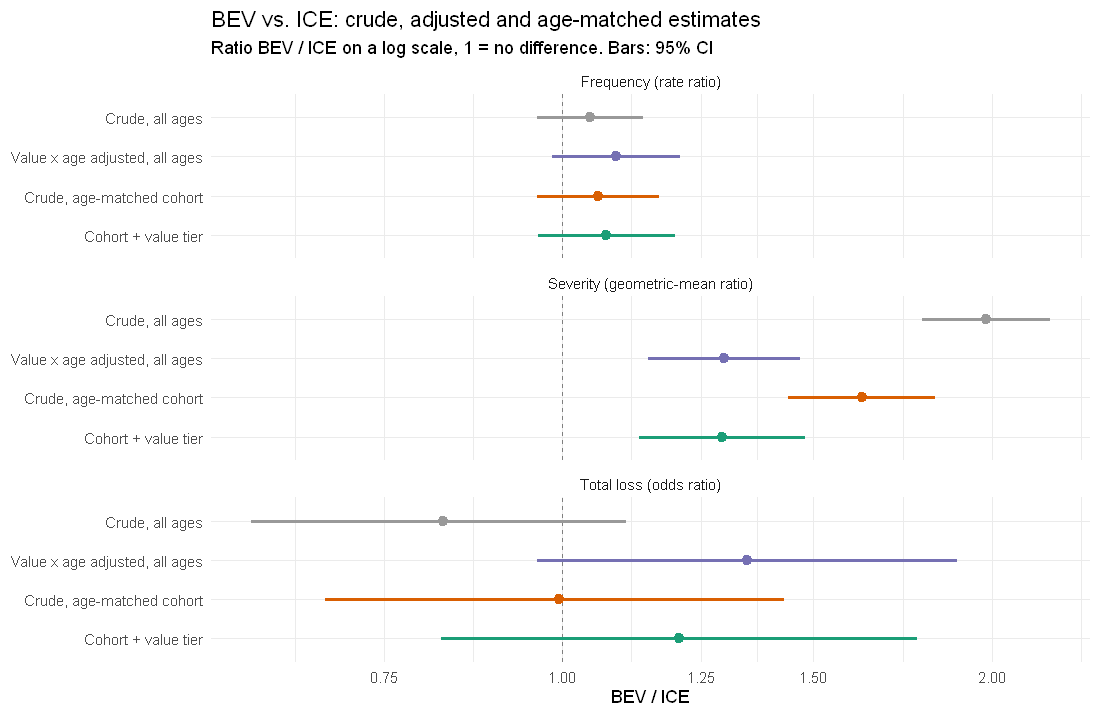

In [18]:
pick_crude <- function(rows) {
  rows |>
    filter((measure == "Frequency" & test == "Exact Poisson") | (measure == "Severity" & test == "Welch t (log cost)") |
             (measure == "Total loss" & test == "Fisher's exact")) |>
    select(measure, estimate, ci_low, ci_high)
}
pick_adj <- function(rows, s) {
  rows |>
    filter(strata == s, measure %in% c("Frequency: rate ratio", "Severity: geometric-mean ratio", "Total loss: odds ratio")) |>
    transmute(measure = word(measure, 1, sep = ":"), estimate = adjusted, ci_low, ci_high)
}

forest <- bind_rows(
  `Crude, all ages`                  = pick_crude(overall),
  `Value x age adjusted, all ages`   = pick_adj(h4, "Value tier x age group"),
  `Crude, age-matched cohort`        = pick_crude(cohort),
  `Cohort + value tier`              = pick_adj(cohort_pooled, "Value tier"),
  .id = "basis") |>
  mutate(basis   = fct_rev(fct_inorder(basis)),
         measure = case_when(measure == "Frequency" ~ "Frequency (rate ratio)",
                             measure == "Severity"  ~ "Severity (geometric-mean ratio)",
                             .default = "Total loss (odds ratio)"))

options(repr.plot.height = 6.5)
ggplot(forest, aes(x = estimate, y = basis, colour = basis)) +
  geom_vline(xintercept = 1, linetype = "dashed", colour = "grey50") +
  geom_pointrange(aes(xmin = ci_low, xmax = ci_high), size = 0.6, linewidth = 1) +
  facet_wrap(~ measure, ncol = 1) +
  scale_colour_manual(values = c(`Crude, all ages` = "grey60", `Value x age adjusted, all ages` = "#7570b3",
                                 `Crude, age-matched cohort` = "#d95f02", `Cohort + value tier` = "#1b9e77"),
                      guide = "none") +
  scale_x_log10(breaks = c(0.5, 0.75, 1, 1.25, 1.5, 2, 2.5)) +
  labs(title = "BEV vs. ICE: crude, adjusted and age-matched estimates",
       subtitle = "Ratio BEV / ICE on a log scale, 1 = no difference. Bars: 95% CI",
       x = "BEV / ICE", y = NULL)

**What this means (age-matched cohort)**

*The cohort.* BEV exposure stays above 200 vehicle-years per age up to age 5 and drops to 119 at age 6, so the cutoff is **Vehicle_Age ≤ 5**. This keeps 91% of BEV exposure (562 claims) but only 41% of ICE exposure (1,470 claims). Inside the cohort BEVs are still a bit younger (mean age 1.7 vs. 3.3 years) and worth more (about half of BEV exposure is in the High tier, against 9% for ICE). That is why we also pool over value tiers.

*Frequency (H2).* No difference anywhere. Cohort RR 1.06 (0.96–1.17, p = 0.248); pooled over value tiers 1.07 (p = 0.208); no single tier is significant.

*Severity (H1).* The BEV premium shrinks but holds:
- crude in the cohort: GMR 1.62 (1.44–1.83), p < 0.001;
- pooled over value tiers: **1.29** (1.13–1.48), p < 0.001, about the same as the value × age adjustment on all ages (1.30);
- by tier: about 1.95× in Low, 1.30× in Medium, and 1.10× (not significant) in High. The premium is clearest for cheaper BEVs and fades at the top of the market.

*Total loss (H3).*
- All claims: no difference in the cohort (8.2% vs. 8.2%, OR 0.99) or after pooling over value (OR 1.21, p = 0.372).
- Without theft the picture changes. Crude cohort OR 1.40 (p = 0.098); pooled over value tiers **OR 1.80 (1.18–2.74), p = 0.006**. Most of this comes from the Low and Medium tiers. The Low tier has only 37 BEV claims, so its large OR is very uncertain.
- After the Holm correction across all 19 tests (section 7) this result is no longer significant (p_holm ≈ 0.08).

**Answer.** For cars of the same age and similar value, BEV claims still cost about **1.3×** ICE claims, and BEVs do not claim more often. For total loss, a BEV excess appears only once theft is removed and value is held fixed (about 1.8× the odds). That is a lead to check in the logistic GLM, not a settled result.

## 7. Summary of Results
The table collects the main test for each hypothesis on the full data, inside the age-matched cohort, and inside the cohort with value tiers pooled. `p_holm` applies a Holm correction across all rows.

In [19]:
# Pull one test from a test_rows() table
get_test <- function(rows, m, t) filter(rows, measure == m, test == t)
get_adj  <- function(rows, s, m) filter(rows, strata == s, measure == m)
ratio    <- function(x) number(x, accuracy = 0.01)
signif   <- function(p, yes, no) if_else(p < 0.05, yes, no)

sev_wx  <- get_test(overall, "Severity", "Wilcoxon (log cost)");   sev_wt  <- get_test(overall, "Severity", "Welch t (log cost)")
frq     <- get_test(overall, "Frequency", "Exact Poisson");        inc     <- get_test(overall, "Claim incidence", "Chi-square")
tl_p    <- get_test(overall, "Total loss", "Proportion test");     tl_f    <- get_test(overall, "Total loss excl. theft", "Fisher's exact")
c_sev_wx <- get_test(cohort, "Severity", "Wilcoxon (log cost)");   c_sev_wt <- get_test(cohort, "Severity", "Welch t (log cost)")
c_frq    <- get_test(cohort, "Frequency", "Exact Poisson");        c_inc    <- get_test(cohort, "Claim incidence", "Chi-square")
c_tl_p   <- get_test(cohort, "Total loss", "Proportion test");     c_tl_f   <- get_test(cohort, "Total loss excl. theft", "Fisher's exact")
h4_sev <- get_adj(h4, "Value tier x age group", "Severity: geometric-mean ratio")
h4_inc <- get_adj(h4, "Value tier x age group", "Claim incidence: odds ratio")
h4_tl  <- get_adj(h4, "Value tier x age group", "Total loss: odds ratio")
cv_sev <- get_adj(cohort_pooled, "Value tier", "Severity: geometric-mean ratio")
cv_frq <- get_adj(cohort_pooled, "Value tier", "Frequency: rate ratio")
cv_tl  <- get_adj(cohort_pooled, "Value tier", "Total loss: odds ratio")
cv_tln <- get_adj(cohort_pooled, "Value tier", "Total loss excl. theft: odds ratio")
cohort_lbl <- paste0("age <= ", age_cutoff)

summary_table <- tribble(
  ~hypothesis, ~test, ~null_hypothesis, ~statistic, ~p_value, ~takeaway,
  # Full BEV/ICE data
  "H1 Severity", "Wilcoxon rank-sum", "BEV and ICE costs have the same distribution",
    sev_wx$statistic, sev_wx$p_value, paste0("Crude BEV cost about ", ratio(sev_wx$estimate), "x ICE"),
  "H1 Severity", "Welch t-test (log cost)", "Equal mean log cost",
    sev_wt$statistic, sev_wt$p_value, paste0("Same on the log scale: GMR ", ratio(sev_wt$estimate)),
  "H2 Frequency", "Exact Poisson rate test", "BEV rate = ICE rate",
    frq$statistic, frq$p_value, signif(frq$p_value, "BEV frequency differs from ICE", paste0("No significant frequency gap (RR ", ratio(frq$estimate), ")")),
  "H2 Frequency", "Chi-square (0 vs 1+ claims)", "Claim incidence independent of powertrain",
    inc$statistic, inc$p_value, signif(inc$p_value, "Share with a claim differs", "Same share of policies with a claim"),
  "H3 Total loss", "Two-sample proportion test", "Equal total-loss rate",
    tl_p$statistic, tl_p$p_value, paste0("Crude TL rate ", tl_p$bev, " vs. ", tl_p$ice, signif(tl_p$p_value, "", ", not significant")),
  "H3 Total loss", "Fisher's exact (excl. theft)", "Odds ratio = 1",
    tl_f$statistic, tl_f$p_value, signif(tl_f$p_value, "TL odds differ without theft", "No difference once theft is removed"),
  # Stratified on all ages
  "H4 Confounding", "Severity adjusted for value x age", "Adjusted ratio = 1",
    paste("GMR =", ratio(h4_sev$adjusted)), h4_sev$p_value, paste0("BEV premium shrinks to ", ratio(h4_sev$adjusted), "x after value and age"),
  "H4 Confounding", "CMH, claim incidence by value x age", "Common OR = 1",
    paste("OR =", ratio(h4_inc$adjusted)), h4_inc$p_value, signif(h4_inc$p_value, "Incidence differs after value and age", "Incidence still no different after value and age"),
  "H4 Confounding", "CMH, total loss by value x age", "Common OR = 1",
    paste("OR =", ratio(h4_tl$adjusted)), h4_tl$p_value, paste0("OR moves from ", ratio(h4_tl$crude), " to ", ratio(h4_tl$adjusted), signif(h4_tl$p_value, "", ", not significant")),
  # Age-matched cohort, crude
  "H1 Severity (cohort)", paste0("Wilcoxon rank-sum, ", cohort_lbl), "Same cost distribution",
    c_sev_wx$statistic, c_sev_wx$p_value, paste0("Same-age BEV cost about ", ratio(c_sev_wx$estimate), "x ICE"),
  "H1 Severity (cohort)", paste0("Welch t-test (log cost), ", cohort_lbl), "Equal mean log cost",
    c_sev_wt$statistic, c_sev_wt$p_value, paste0("GMR ", ratio(c_sev_wt$estimate), " in the cohort"),
  "H2 Frequency (cohort)", paste0("Exact Poisson rate test, ", cohort_lbl), "BEV rate = ICE rate",
    c_frq$statistic, c_frq$p_value, signif(c_frq$p_value, paste0("Same-age BEV frequency differs (RR ", ratio(c_frq$estimate), ")"), paste0("No significant frequency gap (RR ", ratio(c_frq$estimate), ")")),
  "H2 Frequency (cohort)", paste0("Chi-square (0 vs 1+ claims), ", cohort_lbl), "Incidence independent of powertrain",
    c_inc$statistic, c_inc$p_value, signif(c_inc$p_value, "Share with a claim differs", "Same share of policies with a claim"),
  "H3 Total loss (cohort)", paste0("Two-sample proportion test, ", cohort_lbl), "Equal total-loss rate",
    c_tl_p$statistic, c_tl_p$p_value, paste0("TL rate ", c_tl_p$bev, " vs. ", c_tl_p$ice, signif(c_tl_p$p_value, "", ", not significant")),
  "H3 Total loss (cohort)", paste0("Fisher's exact (excl. theft), ", cohort_lbl), "Odds ratio = 1",
    c_tl_f$statistic, c_tl_f$p_value, paste0("OR ", ratio(c_tl_f$estimate), signif(c_tl_f$p_value, ", significant", ", not significant")),
  # Age-matched cohort, value tiers pooled
  "H1 Severity (cohort + value)", "lm(log cost ~ Powertrain + value_tier)", "Adjusted ratio = 1",
    paste("GMR =", ratio(cv_sev$adjusted)), cv_sev$p_value, paste0("Same age and value tier: BEV cost ", ratio(cv_sev$adjusted), "x ICE"),
  "H2 Frequency (cohort + value)", "MH rate ratio by value tier", "Common RR = 1",
    paste("RR =", ratio(cv_frq$adjusted)), cv_frq$p_value, signif(cv_frq$p_value, paste0("BEV frequency differs (RR ", ratio(cv_frq$adjusted), ")"), paste0("No significant frequency gap (RR ", ratio(cv_frq$adjusted), ")")),
  "H3 Total loss (cohort + value)", "CMH, total loss by value tier", "Common OR = 1",
    paste("OR =", ratio(cv_tl$adjusted)), cv_tl$p_value, paste0("Same age and value tier: OR ", ratio(cv_tl$adjusted), signif(cv_tl$p_value, ", significant", ", not significant")),
  "H3 Total loss (cohort + value)", "CMH, total loss excl. theft by value tier", "Common OR = 1",
    paste("OR =", ratio(cv_tln$adjusted)), cv_tln$p_value, paste0("Without theft: OR ", ratio(cv_tln$adjusted), signif(cv_tln$p_value, ", significant", ", not significant"))
) |>
  mutate(decision = if_else(p_value < 0.05, "Reject H0", "Do not reject H0"),
         p_holm   = p.adjust(p_value, method = "holm"),
         decision_holm = if_else(p_holm < 0.05, "Reject H0", "Do not reject H0"),
         takeaway = if_else(p_value < 0.05 & p_holm >= 0.05, paste0(takeaway, " (not after Holm)"), takeaway),
         .before = takeaway)

summary_table |>
  mutate(across(c(p_value, p_holm), fmt_p))

hypothesis,test,null_hypothesis,statistic,p_value,decision,p_holm,decision_holm,takeaway
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
H1 Severity,Wilcoxon rank-sum,BEV and ICE costs have the same distribution,"W = 1,532,146",< 0.001,Reject H0,< 0.001,Reject H0,Crude BEV cost about 2.01x ICE
H1 Severity,Welch t-test (log cost),Equal mean log cost,t = 12.98,< 0.001,Reject H0,< 0.001,Reject H0,Same on the log scale: GMR 1.98
H2 Frequency,Exact Poisson rate test,BEV rate = ICE rate,RR = 1.046,0.294,Do not reject H0,1.000,Do not reject H0,No significant frequency gap (RR 1.05)
H2 Frequency,Chi-square (0 vs 1+ claims),Claim incidence independent of powertrain,X² = 0.67,0.413,Do not reject H0,1.000,Do not reject H0,Same share of policies with a claim
H3 Total loss,Two-sample proportion test,Equal total-loss rate,X² = 1.51,0.219,Do not reject H0,1.000,Do not reject H0,"Crude TL rate 9.0% vs. 10.7%, not significant"
H3 Total loss,Fisher's exact (excl. theft),Odds ratio = 1,OR = 1.05,0.753,Do not reject H0,1.000,Do not reject H0,No difference once theft is removed
H4 Confounding,Severity adjusted for value x age,Adjusted ratio = 1,GMR = 1.30,< 0.001,Reject H0,< 0.001,Reject H0,BEV premium shrinks to 1.30x after value and age
H4 Confounding,"CMH, claim incidence by value x age",Common OR = 1,OR = 1.08,0.200,Do not reject H0,1.000,Do not reject H0,Incidence still no different after value and age
H4 Confounding,"CMH, total loss by value x age",Common OR = 1,OR = 1.35,0.090,Do not reject H0,1.000,Do not reject H0,"OR moves from 0.83 to 1.35, not significant"


`p_holm` applies a Holm correction across all 19 rows. It changes one decision: the cohort total-loss result without theft (raw p = 0.006) is no longer significant after the correction.

| Hypothesis | Result | Actuarial takeaway |
|---|---|---|
| **H1** Severity higher for BEV | **Supported.** Crude ≈ 2.0×; ≈ 1.3× at the same age and similar value (on all ages and in the age-matched cohort) | Most of the cost gap is vehicle value, which the tariff already rates. A BEV severity loading of roughly +25–30% on top of value is justified. |
| **H2** Frequency not higher for BEV | **Supported.** RR ≈ 1.05–1.09 in the main versions, none significant. Only the value-tier-only adjustment in §5.2 dips below 5% (RR 1.11) | No BEV frequency loading. The GLM should confirm this with all factors in. |
| **H3** Total loss higher for BEV | **Not supported** on all claims. Without theft, at equal age and value, OR ≈ 1.8, but not significant after Holm | Too few BEV total losses for a firm answer. Test it in a logistic GLM with value, age and claim type. |
| **H4** Confounding by value / age | **Supported.** Severity and total-loss estimates move a lot; driver age changes nothing | Value and vehicle age must be in every model, or the BEV effect will be wrong. |

**Next step: notebook 04.** The tests here adjust for one or two variables at a time. Notebook 04 fits GLMs with all rating factors together:
- **Frequency:** Poisson or Negative Binomial with `offset(log(exposure))`.
- **Severity:** Gamma with a log link and `log(Vehicle_Value)` as a covariate.
- **Total loss:** logistic GLM, with theft handled separately.

Based on the tests above, we expect a frequency relativity close to 1.0, a severity relativity of about 1.25–1.3 after value, and a non-theft total-loss effect that may be above 1 but is uncertain.